In [11]:
import pandas as pd
# import scikit-learn as sk
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

df = pd.read_csv("/kaggle/input/datasets/rahmahdaniahfitri/gangguan-tidur-dataset/dataset_GANGGUAN_TIDUR.csv")

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("Jumlah seluruh sel:", df.size)
print("\nInformasi dataset:")
df.info()

Jumlah baris: 100000
Jumlah kolom: 32
Jumlah seluruh sel: 3200000

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 32 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    90000 non-null   float64
 1   age                          90000 non-null   float64
 2   gender                       90000 non-null   object 
 3   occupation                   90000 non-null   object 
 4   bmi                          90000 non-null   float64
 5   country                      90000 non-null   object 
 6   sleep_duration_hrs           90000 non-null   float64
 7   sleep_quality_score          90000 non-null   float64
 8   rem_percentage               90000 non-null   float64
 9   deep_sleep_percentage        90000 non-null   float64
 10  sleep_latency_mins           90000 non-null   float64
 11  wake_episodes_per_night      900

In [12]:
kolom_numerik = df.select_dtypes(include=np.number).columns.tolist()
kolom_kategorikal = df.select_dtypes(include=["object", "category", "bool", "string"]).columns.tolist()

print("Numerik:", kolom_numerik)
print("\nKategorikal/non-numerik:", kolom_kategorikal)

Numerik: ['person_id', 'age', 'bmi', 'sleep_duration_hrs', 'sleep_quality_score', 'rem_percentage', 'deep_sleep_percentage', 'sleep_latency_mins', 'wake_episodes_per_night', 'caffeine_mg_before_bed', 'alcohol_units_before_bed', 'screen_time_before_bed_mins', 'exercise_day', 'steps_that_day', 'nap_duration_mins', 'stress_score', 'work_hours_that_day', 'heart_rate_resting_bpm', 'sleep_aid_used', 'shift_work', 'room_temperature_celsius', 'weekend_sleep_diff_hrs', 'cognitive_performance_score', 'felt_rested']

Kategorikal/non-numerik: ['gender', 'occupation', 'country', 'chronotype', 'mental_health_condition', 'season', 'day_type', 'sleep_disorder_risk']


In [13]:
ringkasan_kolom = pd.DataFrame({
    "Tipe Data": df.dtypes.astype(str),
    "Jumlah Terisi": df.notna().sum(),
    "Jumlah Missing": df.isna().sum(),
    "Jumlah Unik": df.nunique(dropna=True)
})
display(ringkasan_kolom)

,Tipe Data,Jumlah Terisi,Jumlah Missing,Jumlah Unik
person_id,float64,90000,10000,90000
age,float64,90000,10000,52
gender,object,90000,10000,3
occupation,object,90000,10000,12
bmi,float64,90000,10000,275
country,object,90000,10000,15
sleep_duration_hrs,float64,90000,10000,750
sleep_quality_score,float64,90000,10000,89
rem_percentage,float64,90000,10000,201
deep_sleep_percentage,float64,90000,10000,250


In [14]:
kolom_numerik = df.select_dtypes(include=np.number).columns.tolist()
kolom_kategorikal = df.select_dtypes(include=["object", "category", "bool", "string"]).columns.tolist()

print("Numerik:", kolom_numerik)
print("\nKategorikal/non-numerik:", kolom_kategorikal)

Numerik: ['person_id', 'age', 'bmi', 'sleep_duration_hrs', 'sleep_quality_score', 'rem_percentage', 'deep_sleep_percentage', 'sleep_latency_mins', 'wake_episodes_per_night', 'caffeine_mg_before_bed', 'alcohol_units_before_bed', 'screen_time_before_bed_mins', 'exercise_day', 'steps_that_day', 'nap_duration_mins', 'stress_score', 'work_hours_that_day', 'heart_rate_resting_bpm', 'sleep_aid_used', 'shift_work', 'room_temperature_celsius', 'weekend_sleep_diff_hrs', 'cognitive_performance_score', 'felt_rested']

Kategorikal/non-numerik: ['gender', 'occupation', 'country', 'chronotype', 'mental_health_condition', 'season', 'day_type', 'sleep_disorder_risk']


**GRAFIK PEMBAGIAN DATA (BALANCED OR INBALANCED)**

,Jumlah,Persentase (%)
sleep_disorder_risk,,
Healthy,54156,54.16
Mild,33479,33.48
Moderate,8299,8.30
Severe,4066,4.07


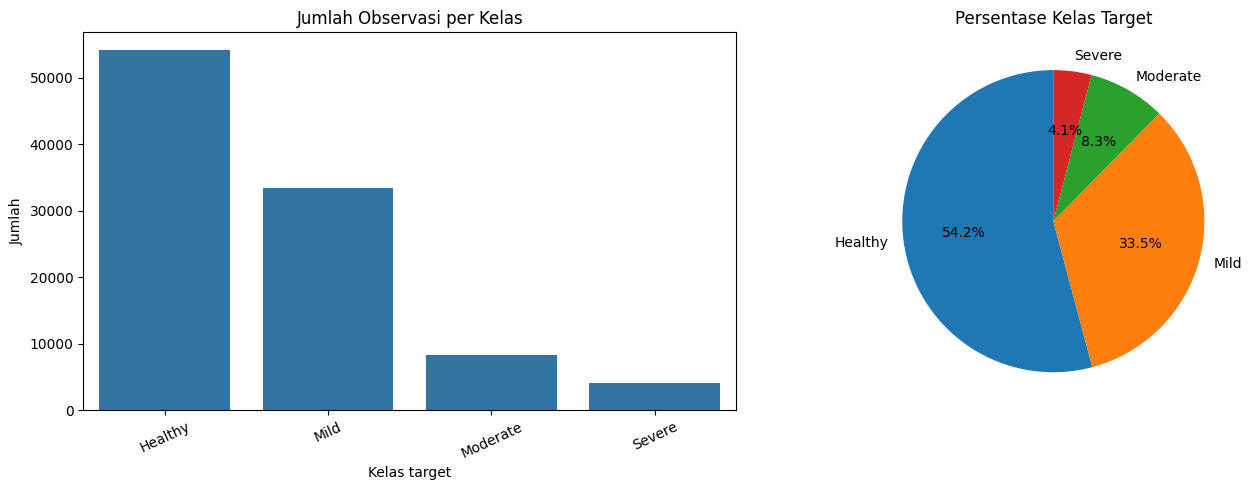

In [15]:
target = "sleep_disorder_risk"

if target not in df.columns:
    print(f"Kolom target '{target}' tidak ditemukan. Ganti variabel target sesuai dataset.")
else:
    jumlah_kelas = df[target].value_counts(dropna=False)
    persen_kelas = df[target].value_counts(normalize=True, dropna=False).mul(100)

    distribusi_target = pd.DataFrame({
        "Jumlah": jumlah_kelas,
        "Persentase (%)": persen_kelas.round(2)
    })
    display(distribusi_target)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.countplot(data=df, x=target, order=jumlah_kelas.index, ax=axes[0])
    axes[0].set_title("Jumlah Observasi per Kelas")
    axes[0].set_xlabel("Kelas target")
    axes[0].set_ylabel("Jumlah")
    axes[0].tick_params(axis="x", rotation=25)

    axes[1].pie(
        jumlah_kelas.values,
        labels=[str(x) for x in jumlah_kelas.index],
        autopct="%1.1f%%",
        startangle=90
    )
    axes[1].set_title("Persentase Kelas Target")

    plt.tight_layout()
    plt.show()

**STATISTIK DESKRIPTIF**

In [16]:
if kolom_numerik:
    display(df[kolom_numerik].describe().T)
else:
    print("Tidak ada kolom numerik.")

,count,mean,std,min,25%,50%,75%,max
person_id,90000.0,50038.686189,28865.037261,1.0,25033.75,50065.50,75051.25,100000.0
age,90000.0,34.701667,11.041289,18.0,26.00,33.00,42.00,69.0
bmi,90000.0,26.291863,4.479712,16.0,23.20,26.30,29.30,45.0
sleep_duration_hrs,90000.0,6.424682,1.275177,3.0,5.53,6.36,7.27,10.5
sleep_quality_score,90000.0,4.869662,1.506569,1.0,3.80,4.90,6.00,10.0
rem_percentage,90000.0,20.239168,3.409049,10.0,18.00,20.30,22.60,30.0
deep_sleep_percentage,90000.0,20.254962,4.243982,5.0,17.40,20.30,23.20,30.0
sleep_latency_mins,90000.0,19.820600,7.586147,1.0,14.00,19.00,25.00,55.0
wake_episodes_per_night,90000.0,3.347633,1.922453,0.0,2.00,3.00,5.00,8.0
caffeine_mg_before_bed,90000.0,38.725000,69.196466,0.0,0.00,0.00,80.00,400.0


In [17]:
for kolom in kolom_kategorikal:
    print(f"\nKolom: {kolom} | Jumlah kategori unik: {df[kolom].nunique(dropna=True)}")
    display(df[kolom].value_counts(dropna=False).head(20).to_frame("Frekuensi"))


Kolom: gender | Jumlah kategori unik: 3


,Frekuensi
gender,
Female,45209
Male,43026
NaN,10000
Other,1765



Kolom: occupation | Jumlah kategori unik: 12


,Frekuensi
occupation,
Student,13383
Software Engineer,10872
NaN,10000
Nurse,9058
Manager,7283
Teacher,7250
Doctor,7080
Freelancer,6321
Retired,6301



Kolom: country | Jumlah kategori unik: 15


...

,Frekuensi
season,
Summer,22663
Spring,22549
Autumn,22405
Winter,22383
NaN,10000



Kolom: day_type | Jumlah kategori unik: 2


,Frekuensi
day_type,
Weekday,64244
Weekend,25756
NaN,10000



Kolom: sleep_disorder_risk | Jumlah kategori unik: 4


,Frekuensi
sleep_disorder_risk,
Healthy,54156
Mild,33479
Moderate,8299
Severe,4066


In [18]:
if kolom_numerik:
    bentuk_distribusi = pd.DataFrame({
        "Skewness": df[kolom_numerik].skew(),
        "Excess Kurtosis": df[kolom_numerik].kurt()
    }).round(3)
    display(bentuk_distribusi)

,Skewness,Excess Kurtosis
person_id,-0.001,-1.200
age,0.552,-0.352
bmi,0.074,-0.178
sleep_duration_hrs,0.219,-0.078
sleep_quality_score,-0.091,-0.423
rem_percentage,-0.119,-0.058
deep_sleep_percentage,-0.111,-0.171
sleep_latency_mins,0.243,-0.085
wake_episodes_per_night,0.455,-0.308
caffeine_mg_before_bed,2.381,6.644


**MISSING VALUE**

In [19]:
missing = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase Missing (%)": (df.isna().mean() * 100).round(2),
    "Jumlah Terisi": df.notna().sum()
}).sort_values("Persentase Missing (%)", ascending=False)

display(missing)

,Jumlah Missing,Persentase Missing (%),Jumlah Terisi
person_id,10000,10.0,90000
age,10000,10.0,90000
gender,10000,10.0,90000
occupation,10000,10.0,90000
bmi,10000,10.0,90000
country,10000,10.0,90000
sleep_duration_hrs,10000,10.0,90000
sleep_quality_score,10000,10.0,90000
rem_percentage,10000,10.0,90000
deep_sleep_percentage,10000,10.0,90000


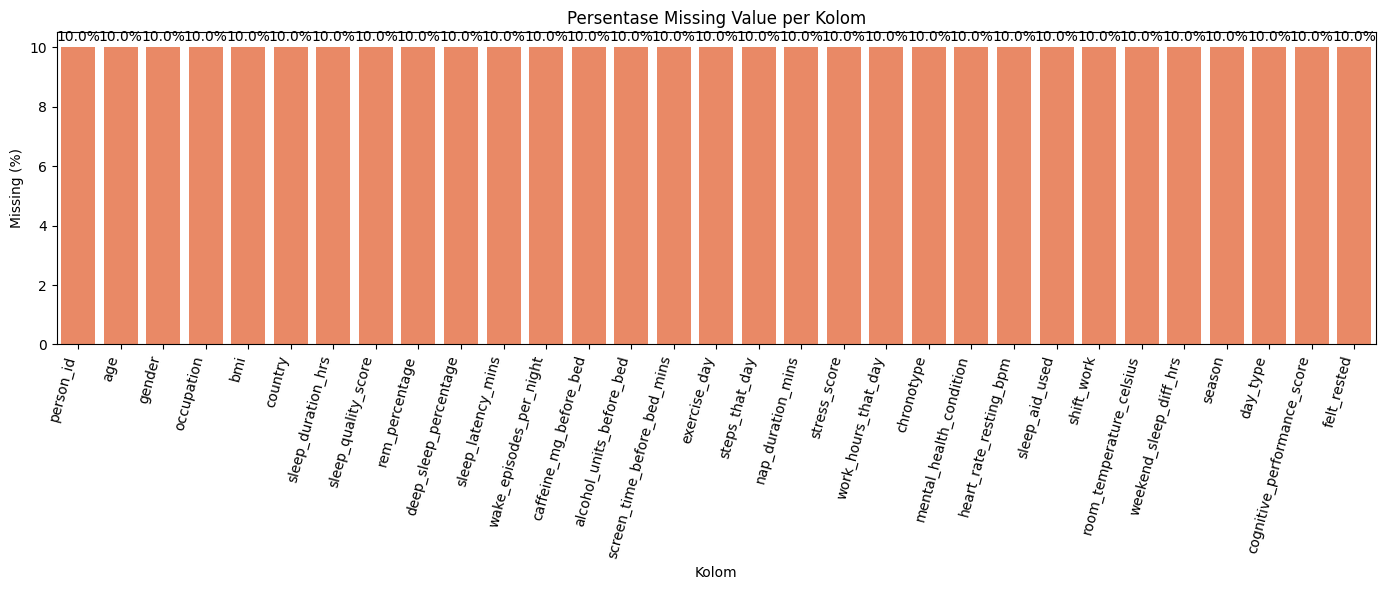

In [20]:
missing_plot = missing[missing["Jumlah Missing"] > 0]

if not missing_plot.empty:
    plt.figure(figsize=(14, 6))
    ax = sns.barplot(
        x=missing_plot.index,
        y=missing_plot["Persentase Missing (%)"],
        color="coral"
    )
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    plt.title("Persentase Missing Value per Kolom")
    plt.xlabel("Kolom")
    plt.ylabel("Missing (%)")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada missing value.")

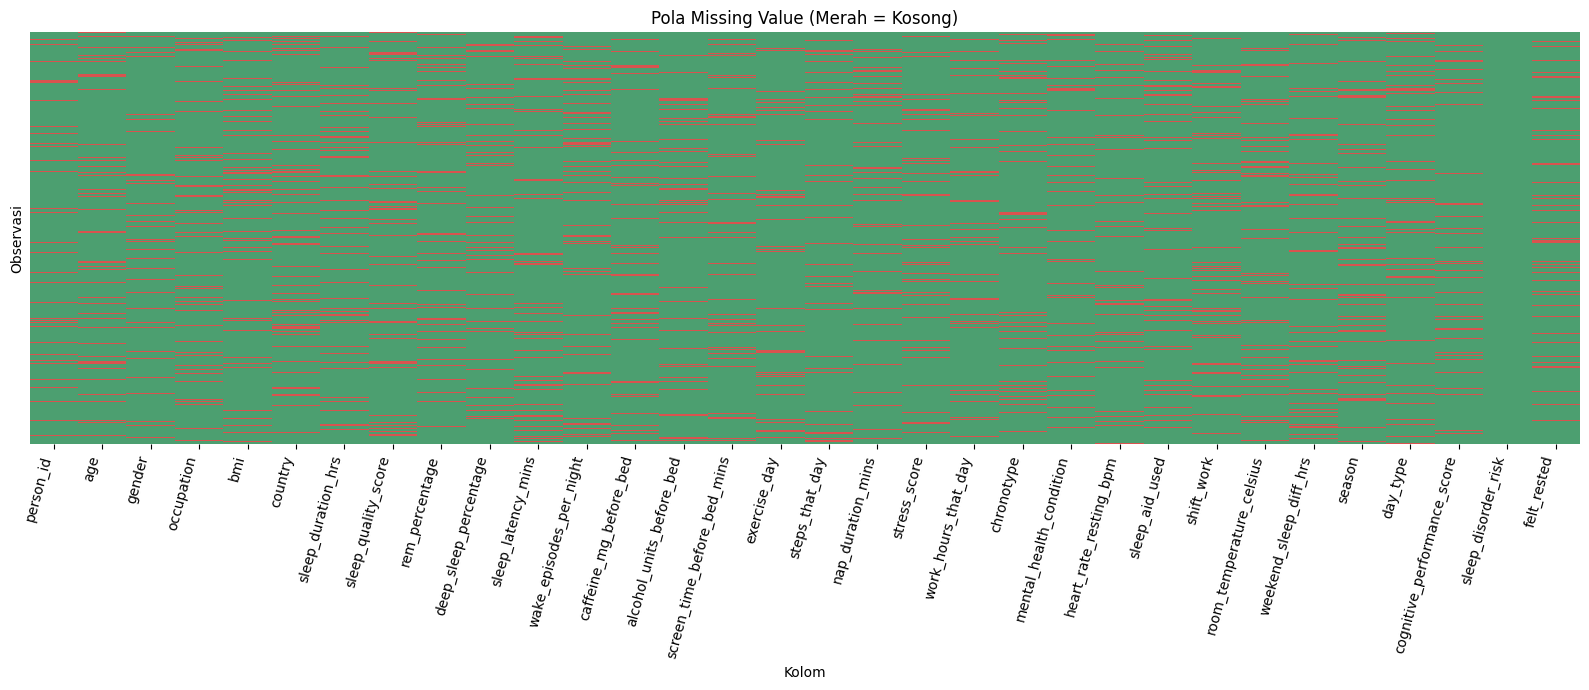

In [21]:
if df.isna().any().any():
    plt.figure(figsize=(16, 7))
    sns.heatmap(
        df.isna(),
        cbar=False,
        yticklabels=False,
        cmap=["#4C9F70", "#D9534F"]
    )
    plt.title("Pola Missing Value (Merah = Kosong)")
    plt.xlabel("Kolom")
    plt.ylabel("Observasi")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada missing value.")

Distribusi jumlah sel kosong per baris:


,Jumlah Baris
0,3801
1,13044
2,21872
3,23808
4,18222
5,10920
6,5327
7,2036
8,719
9,191


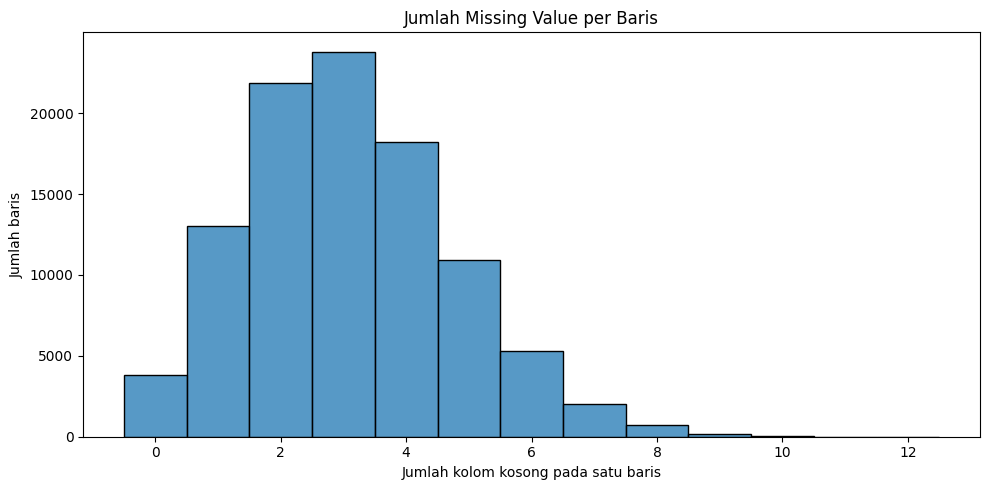

Jumlah baris dengan setidaknya satu missing: 96199


In [22]:
missing_per_baris = df.isna().sum(axis=1)

print("Distribusi jumlah sel kosong per baris:")
display(missing_per_baris.value_counts().sort_index().to_frame("Jumlah Baris"))

plt.figure(figsize=(10, 5))
sns.histplot(missing_per_baris, discrete=True)
plt.title("Jumlah Missing Value per Baris")
plt.xlabel("Jumlah kolom kosong pada satu baris")
plt.ylabel("Jumlah baris")
plt.tight_layout()
plt.show()

print("Jumlah baris dengan setidaknya satu missing:", int((missing_per_baris > 0).sum()))

**IDENTIFIKASI DUPLIKASI DATA**

In [23]:
jumlah_duplikat = int(df.duplicated().sum())
persen_duplikat = jumlah_duplikat / len(df) * 100 if len(df) else 0

print("Jumlah baris duplikat identik:", jumlah_duplikat)
print(f"Persentase baris duplikat: {persen_duplikat:.2f}%")

Jumlah baris duplikat identik: 0
Persentase baris duplikat: 0.00%


In [24]:
baris_duplikat = df[df.duplicated(keep=False)]
print("Jumlah baris yang tergabung dalam kelompok duplikat:", len(baris_duplikat))
display(baris_duplikat.head(30))

Jumlah baris yang tergabung dalam kelompok duplikat: 0


,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,...,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested


In [25]:
if "person_id" in df.columns:
    id_terisi = df["person_id"].dropna()
    id_duplikat = id_terisi[id_terisi.duplicated(keep=False)]
    print("Jumlah nilai person_id non-null yang berada dalam kelompok duplikat:", len(id_duplikat))
    display(id_duplikat.value_counts().head(20).to_frame("Frekuensi"))

Jumlah nilai person_id non-null yang berada dalam kelompok duplikat: 0


,Frekuensi
person_id,


**IDENTIFIKASI OUTLIER**

In [26]:
# Kecualikan kolom identitas dan kolom biner dari analisis outlier.
kolom_dikecualikan_outlier = [
    c for c in ["person_id", "exercise_day", "sleep_aid_used", "shift_work", "felt_rested"]
    if c in kolom_numerik
]
kolom_outlier = [c for c in kolom_numerik if c not in kolom_dikecualikan_outlier]

hasil_outlier = []
for kolom in kolom_outlier:
    x = df[kolom].dropna()
    if x.empty:
        continue
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr
    mask = (x < bawah) | (x > atas)
    hasil_outlier.append({
        "Kolom": kolom,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Batas Bawah": bawah,
        "Batas Atas": atas,
        "Jumlah Kandidat": int(mask.sum()),
        "Persentase (%)": mask.mean() * 100
    })

tabel_outlier = pd.DataFrame(hasil_outlier)
if not tabel_outlier.empty:
    tabel_outlier["Persentase (%)"] = tabel_outlier["Persentase (%)"].round(2)
    display(tabel_outlier.sort_values("Persentase (%)", ascending=False))

,Kolom,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Kandidat,Persentase (%)
9,alcohol_units_before_bed,0.00,1.00,1.00,-1.500,2.500,6787,7.54
10,screen_time_before_bed_mins,30.00,84.00,54.00,-51.000,165.000,5198,5.78
8,caffeine_mg_before_bed,0.00,80.00,80.00,-120.000,200.000,2149,2.39
13,stress_score,4.80,6.80,2.00,1.800,9.800,1940,2.16
15,heart_rate_resting_bpm,62.00,71.00,9.00,48.500,84.500,1173,1.30
12,nap_duration_mins,0.00,30.00,30.00,-45.000,75.000,793,0.88
4,rem_percentage,18.00,22.60,4.60,11.100,29.500,699,0.78
2,sleep_duration_hrs,5.53,7.27,1.74,2.920,9.880,495,0.55
5,deep_sleep_percentage,17.40,23.20,5.80,8.700,31.900,367,0.41
6,sleep_latency_mins,14.00,25.00,11.00,-2.500,41.500,328,0.36


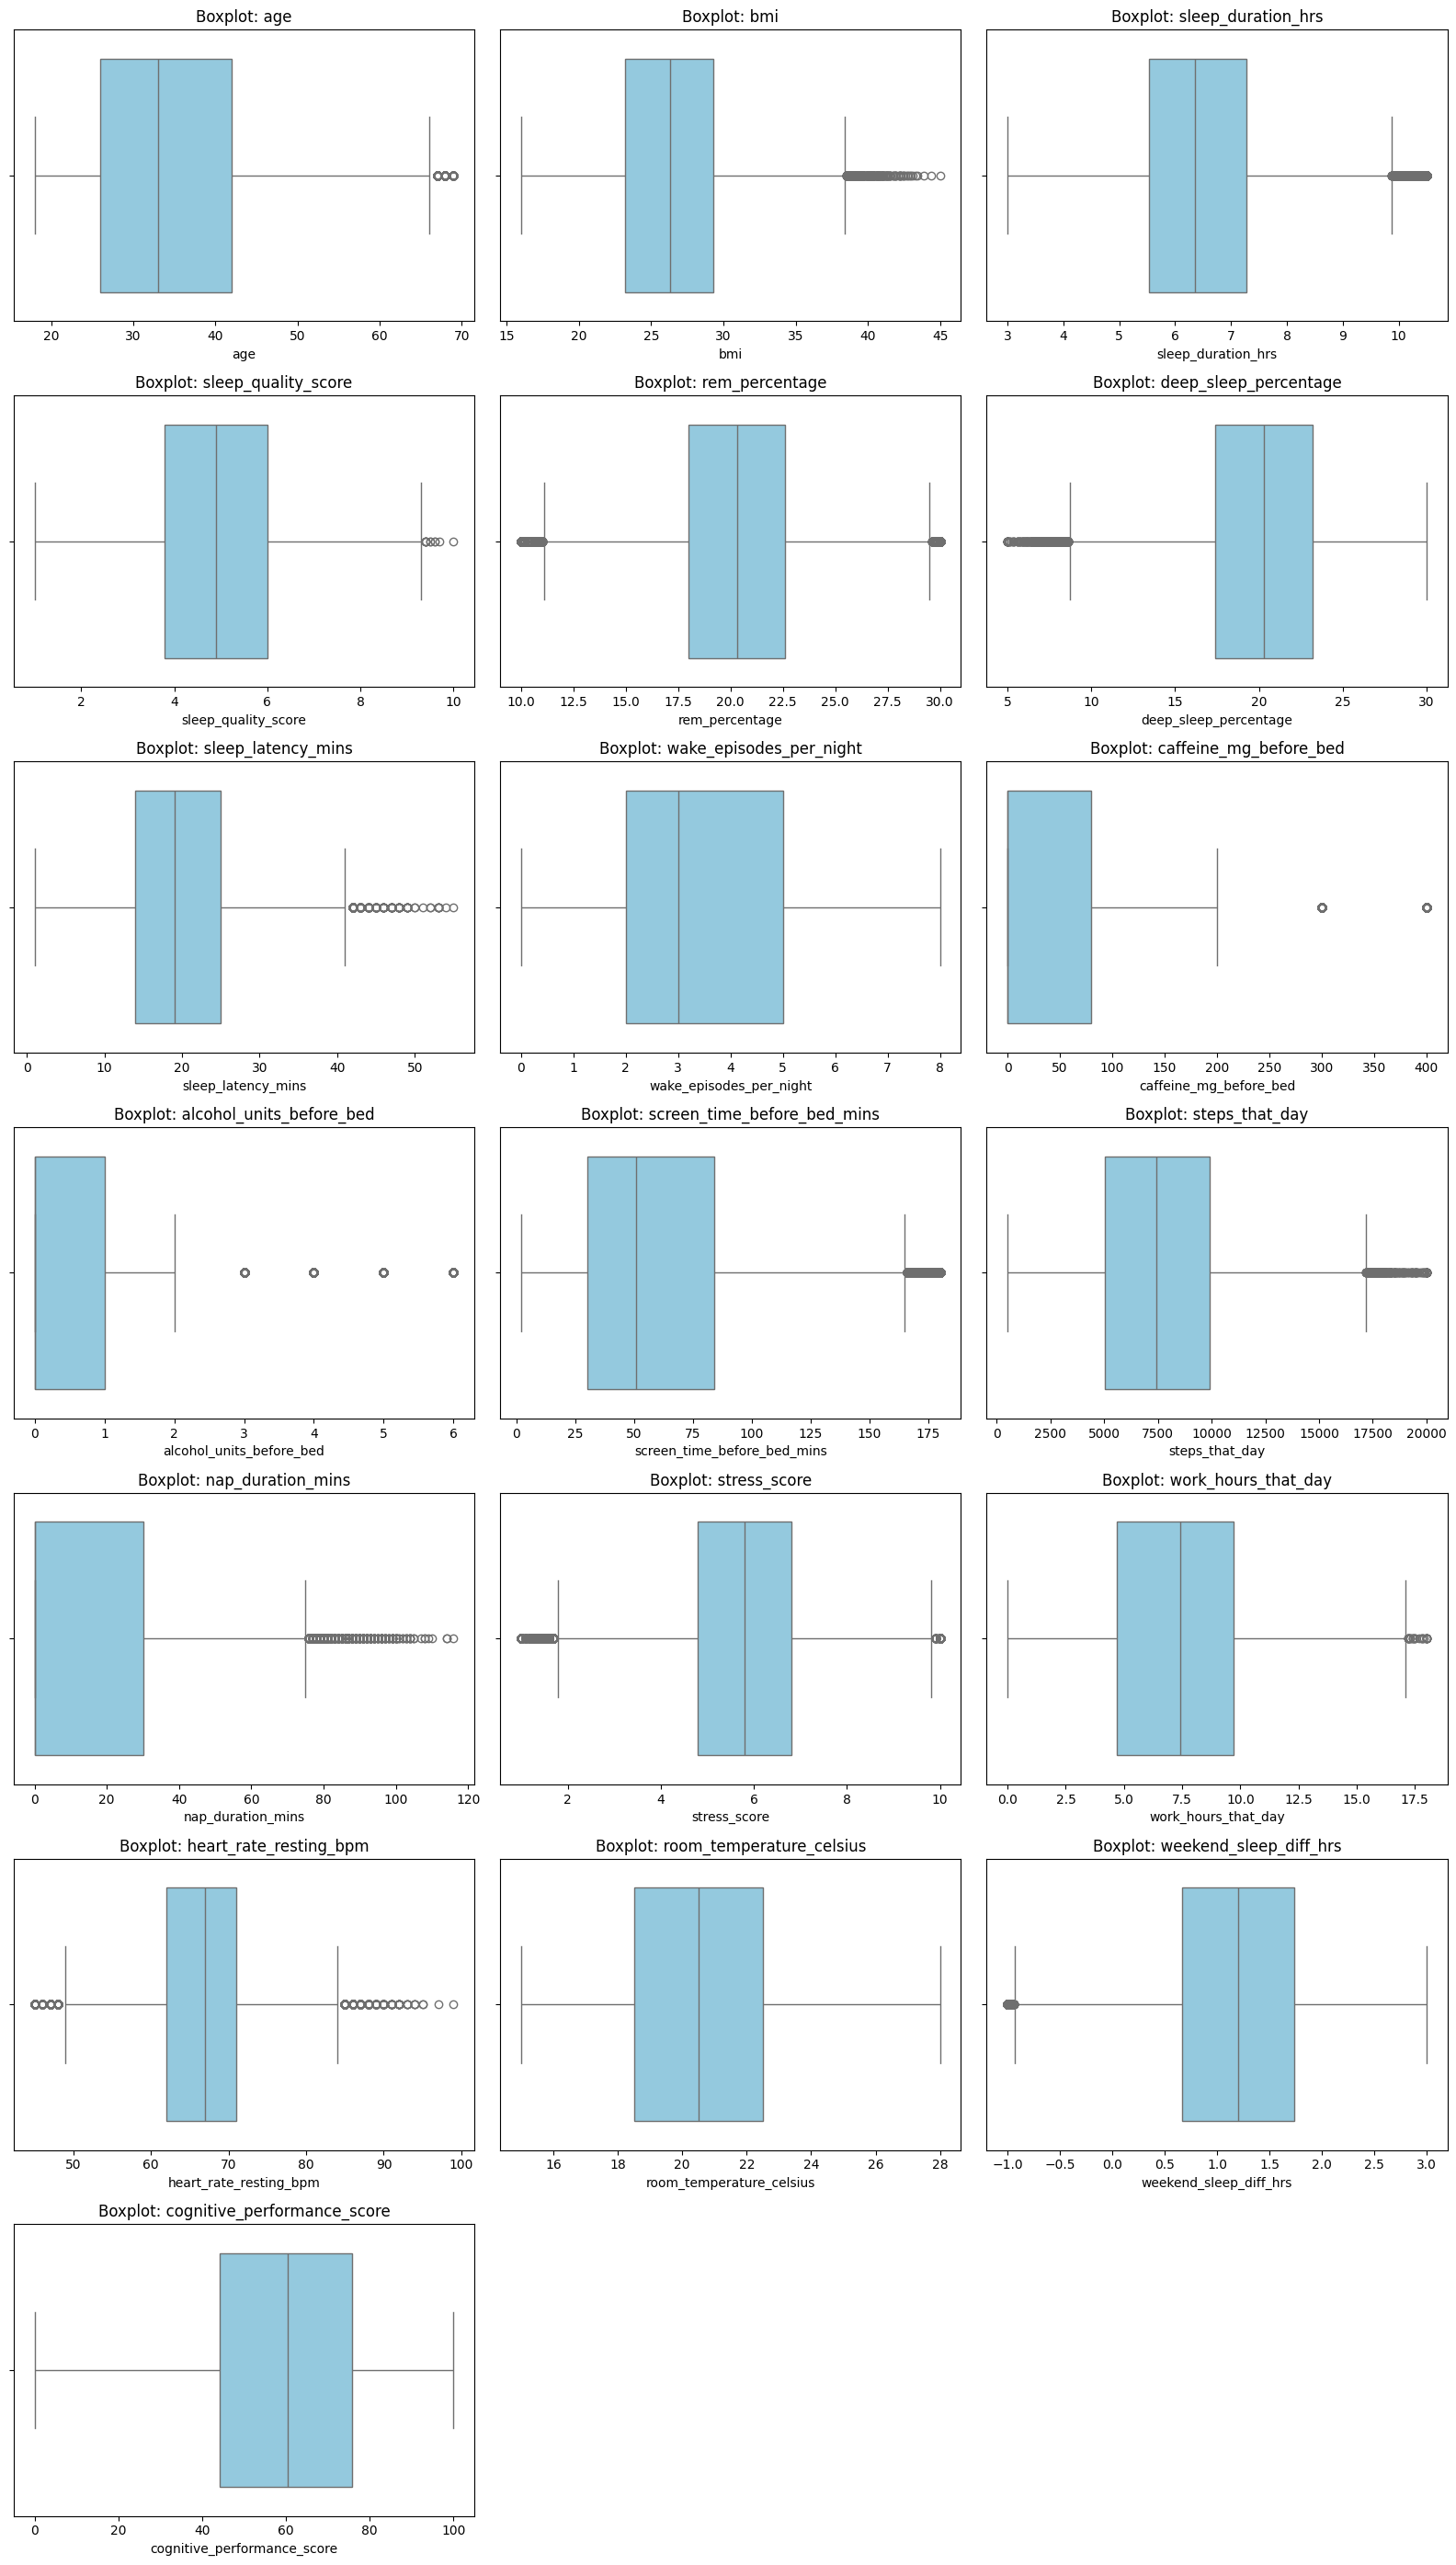

In [27]:
if kolom_outlier:
    ncols = 3
    nrows = int(np.ceil(len(kolom_outlier) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, kolom in enumerate(kolom_outlier):
        sns.boxplot(x=df[kolom], ax=axes[i], color="skyblue")
        axes[i].set_title(f"Boxplot: {kolom}")
        axes[i].set_xlabel(kolom)

    for j in range(len(kolom_outlier), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

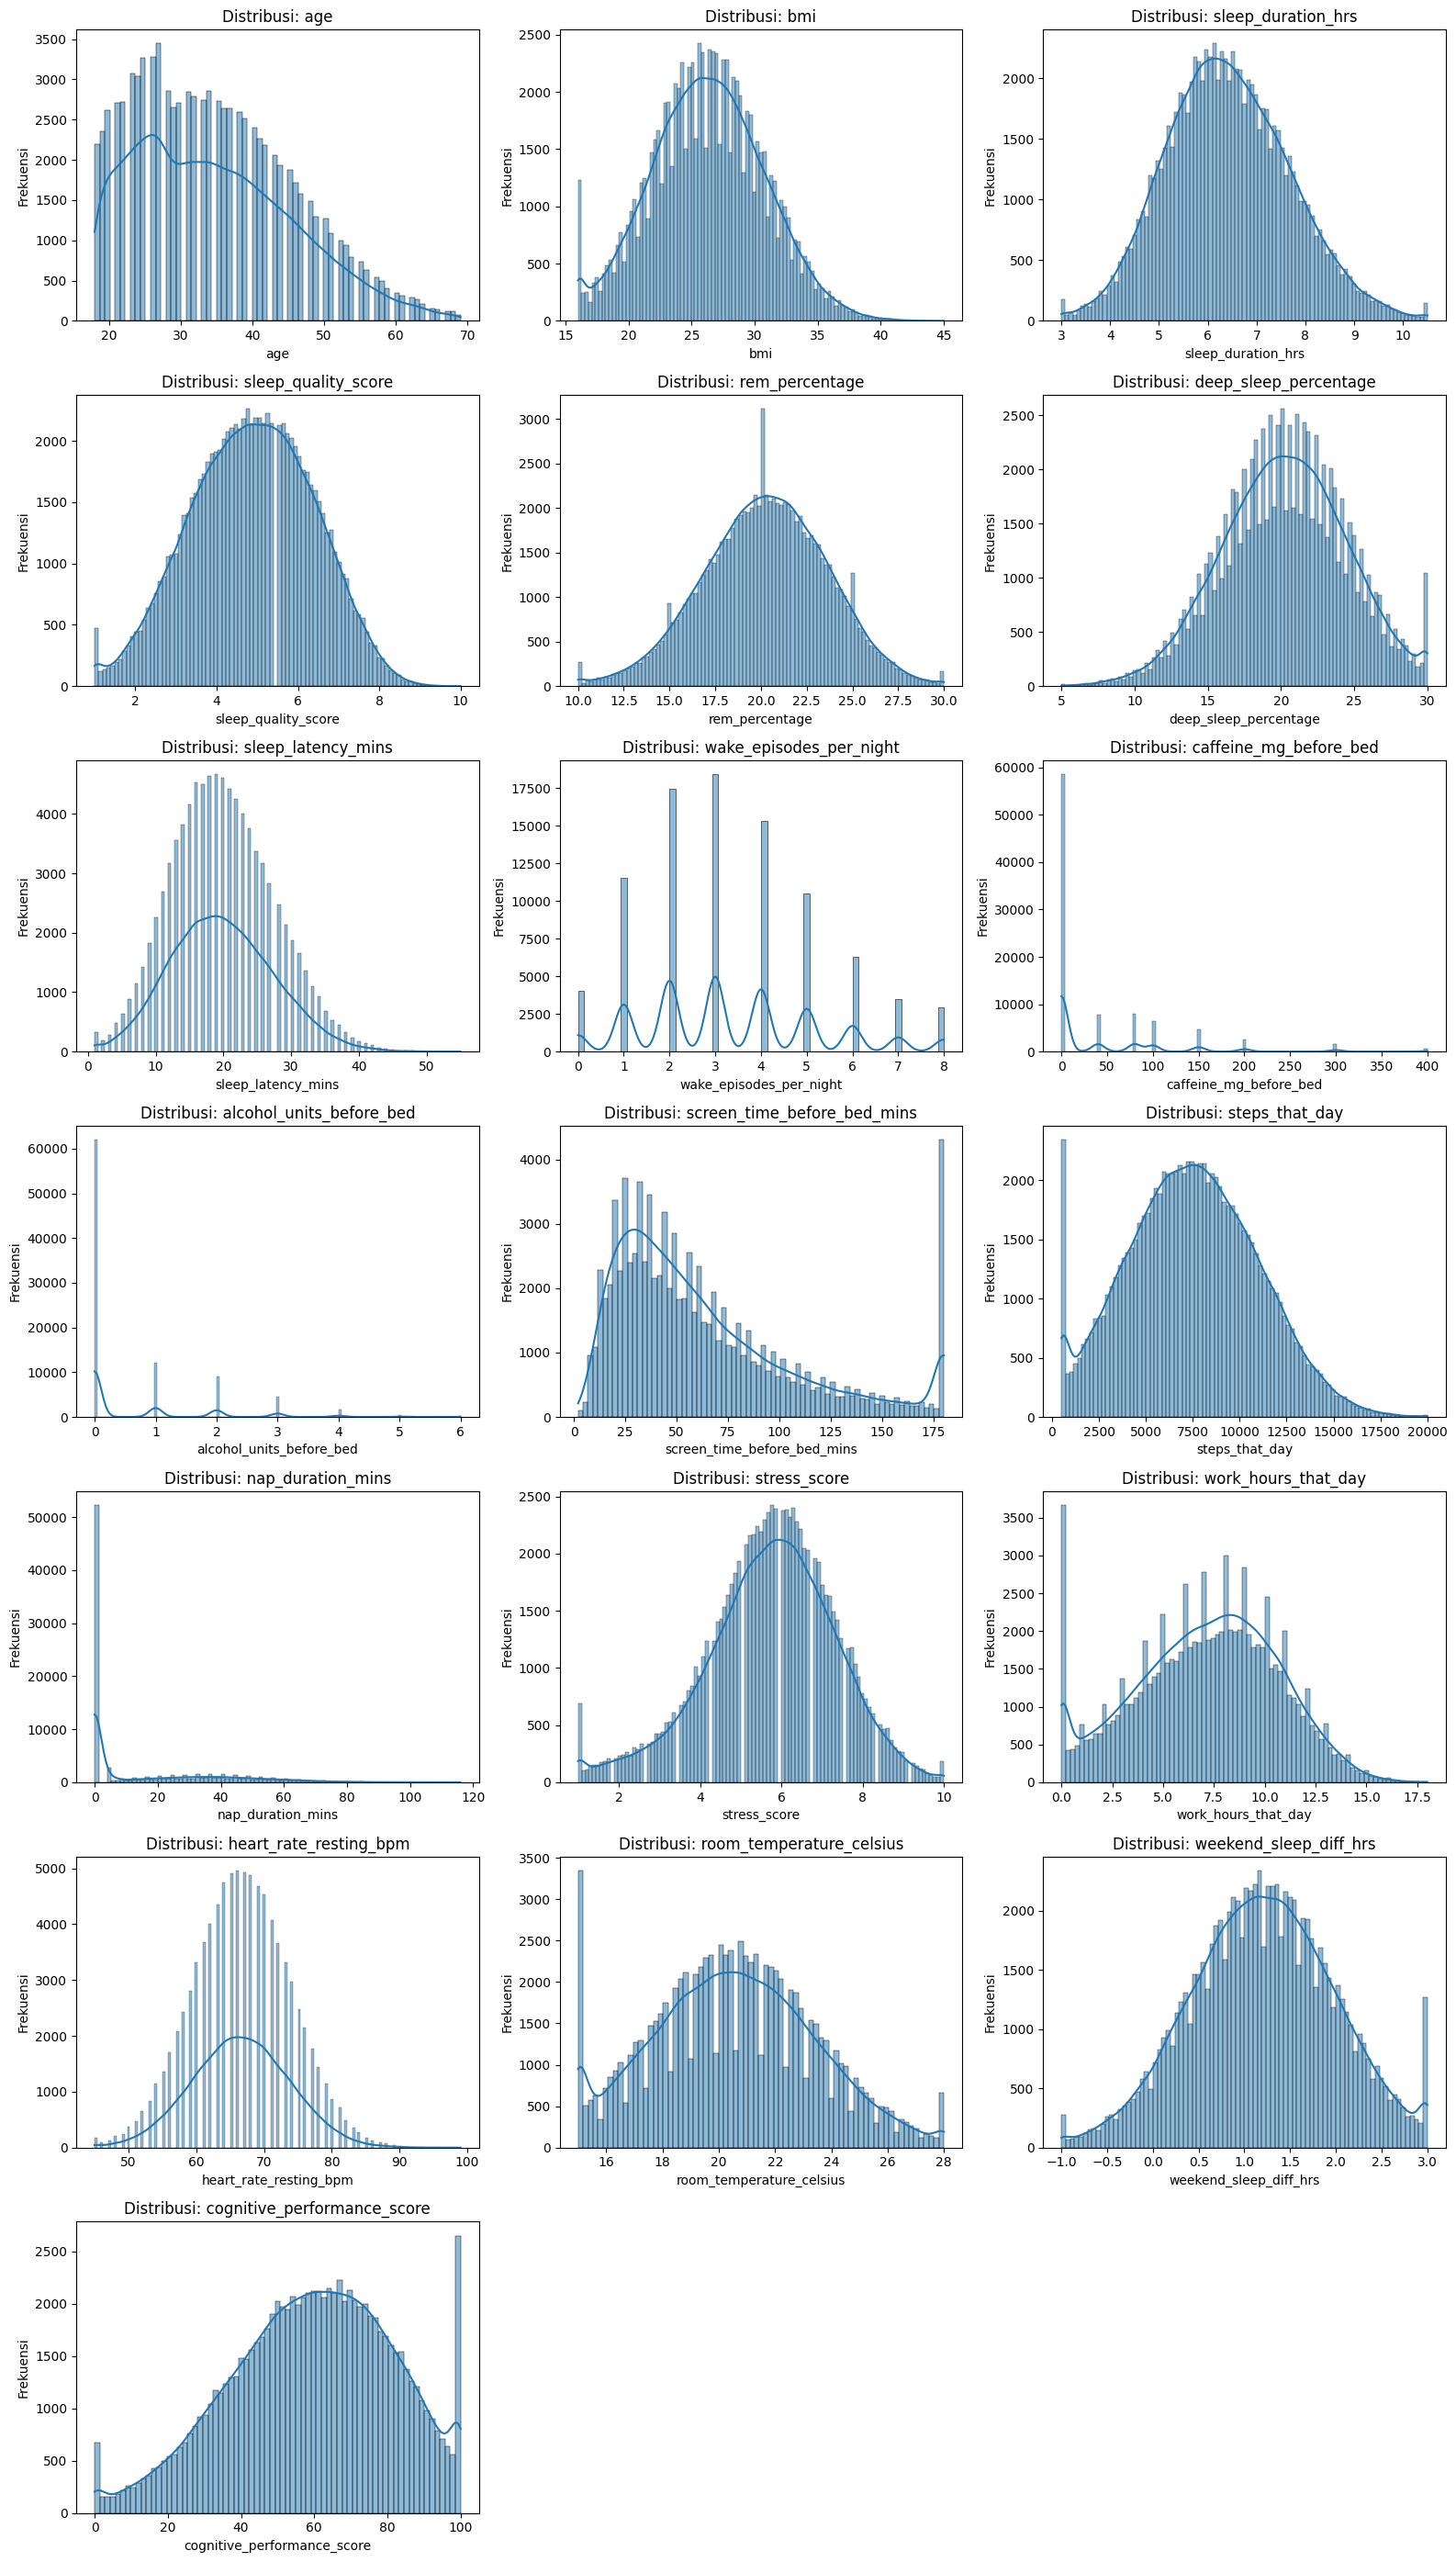

In [28]:
if kolom_outlier:
    ncols = 3
    nrows = int(np.ceil(len(kolom_outlier) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, kolom in enumerate(kolom_outlier):
        sns.histplot(data=df, x=kolom, bins="auto", kde=True, ax=axes[i])
        axes[i].set_title(f"Distribusi: {kolom}")
        axes[i].set_xlabel(kolom)
        axes[i].set_ylabel("Frekuensi")

    for j in range(len(kolom_outlier), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

**VISUALISASI SEMUA DATA**

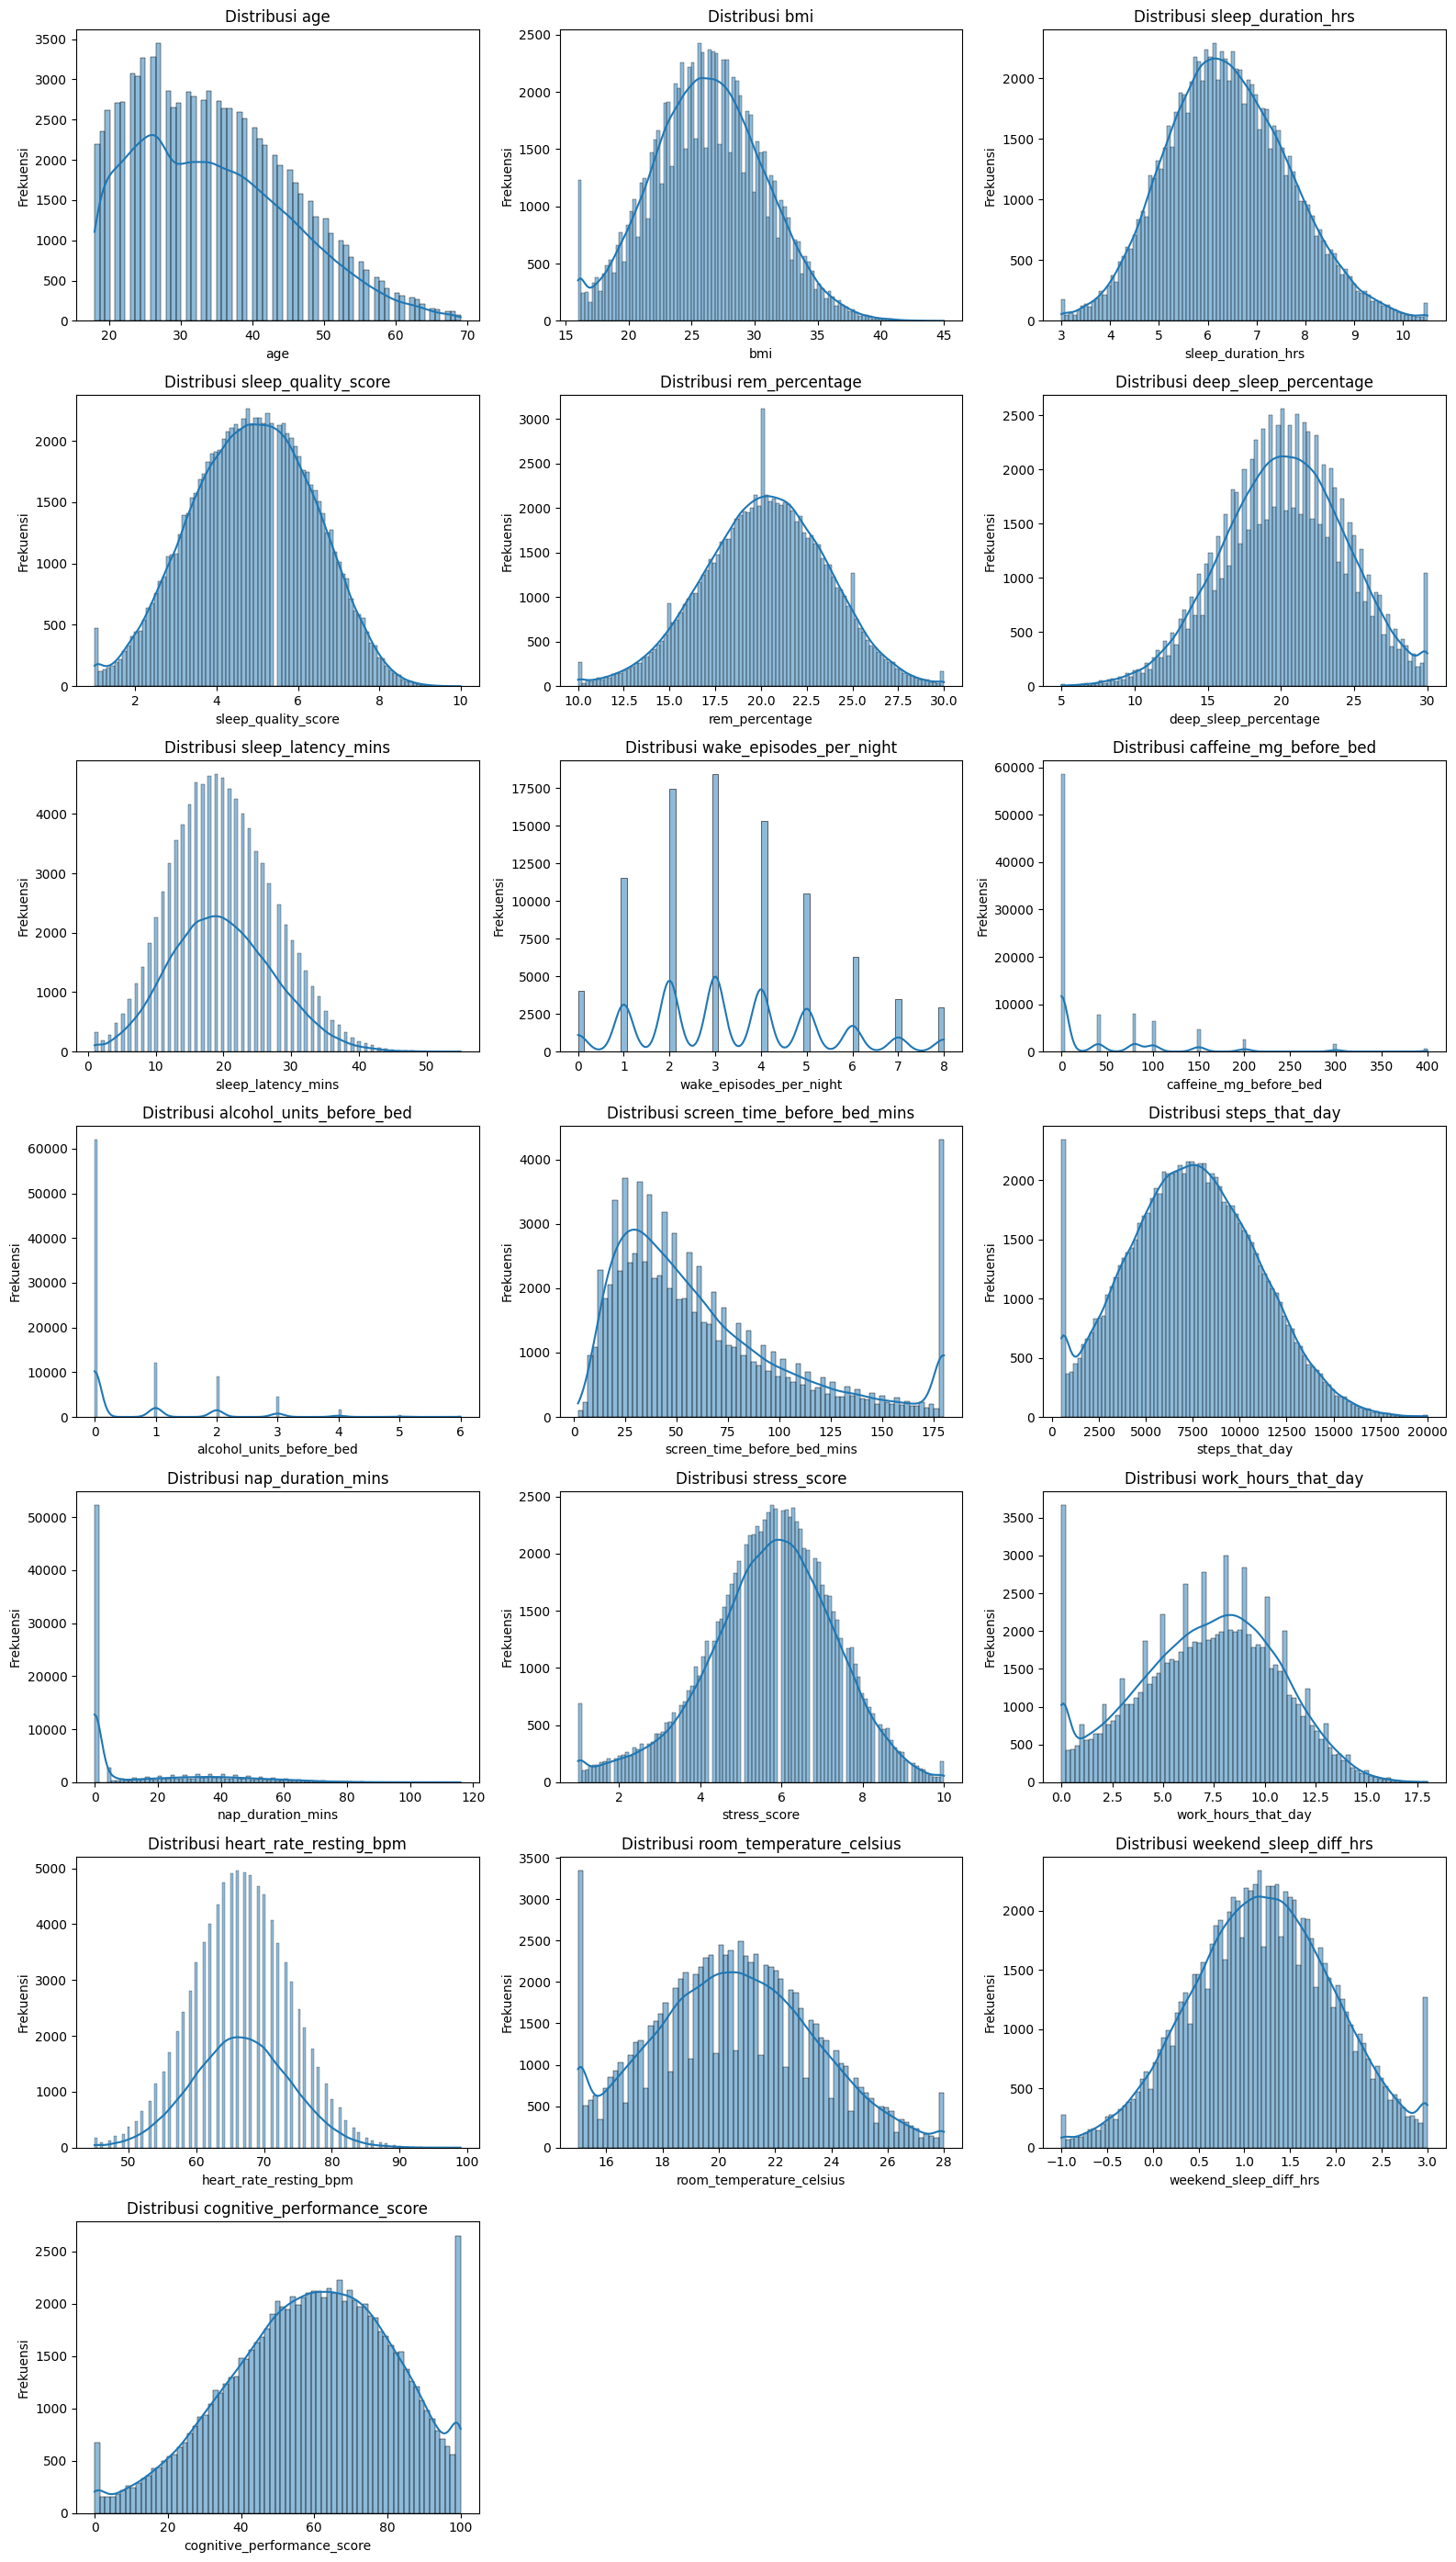

In [29]:
# Variabel biner dan ID dapat dianalisis sebagai kategori; di sini fokus pada pengukuran numerik.
kolom_visual_numerik = [
    c for c in kolom_numerik
    if c not in ["person_id", "exercise_day", "sleep_aid_used", "shift_work", "felt_rested"]
]

if kolom_visual_numerik:
    ncols = 3
    nrows = int(np.ceil(len(kolom_visual_numerik) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, kolom in enumerate(kolom_visual_numerik):
        sns.histplot(data=df, x=kolom, bins="auto", kde=True, ax=axes[i])
        axes[i].set_title(f"Distribusi {kolom}")
        axes[i].set_xlabel(kolom)
        axes[i].set_ylabel("Frekuensi")

    for j in range(len(kolom_visual_numerik), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

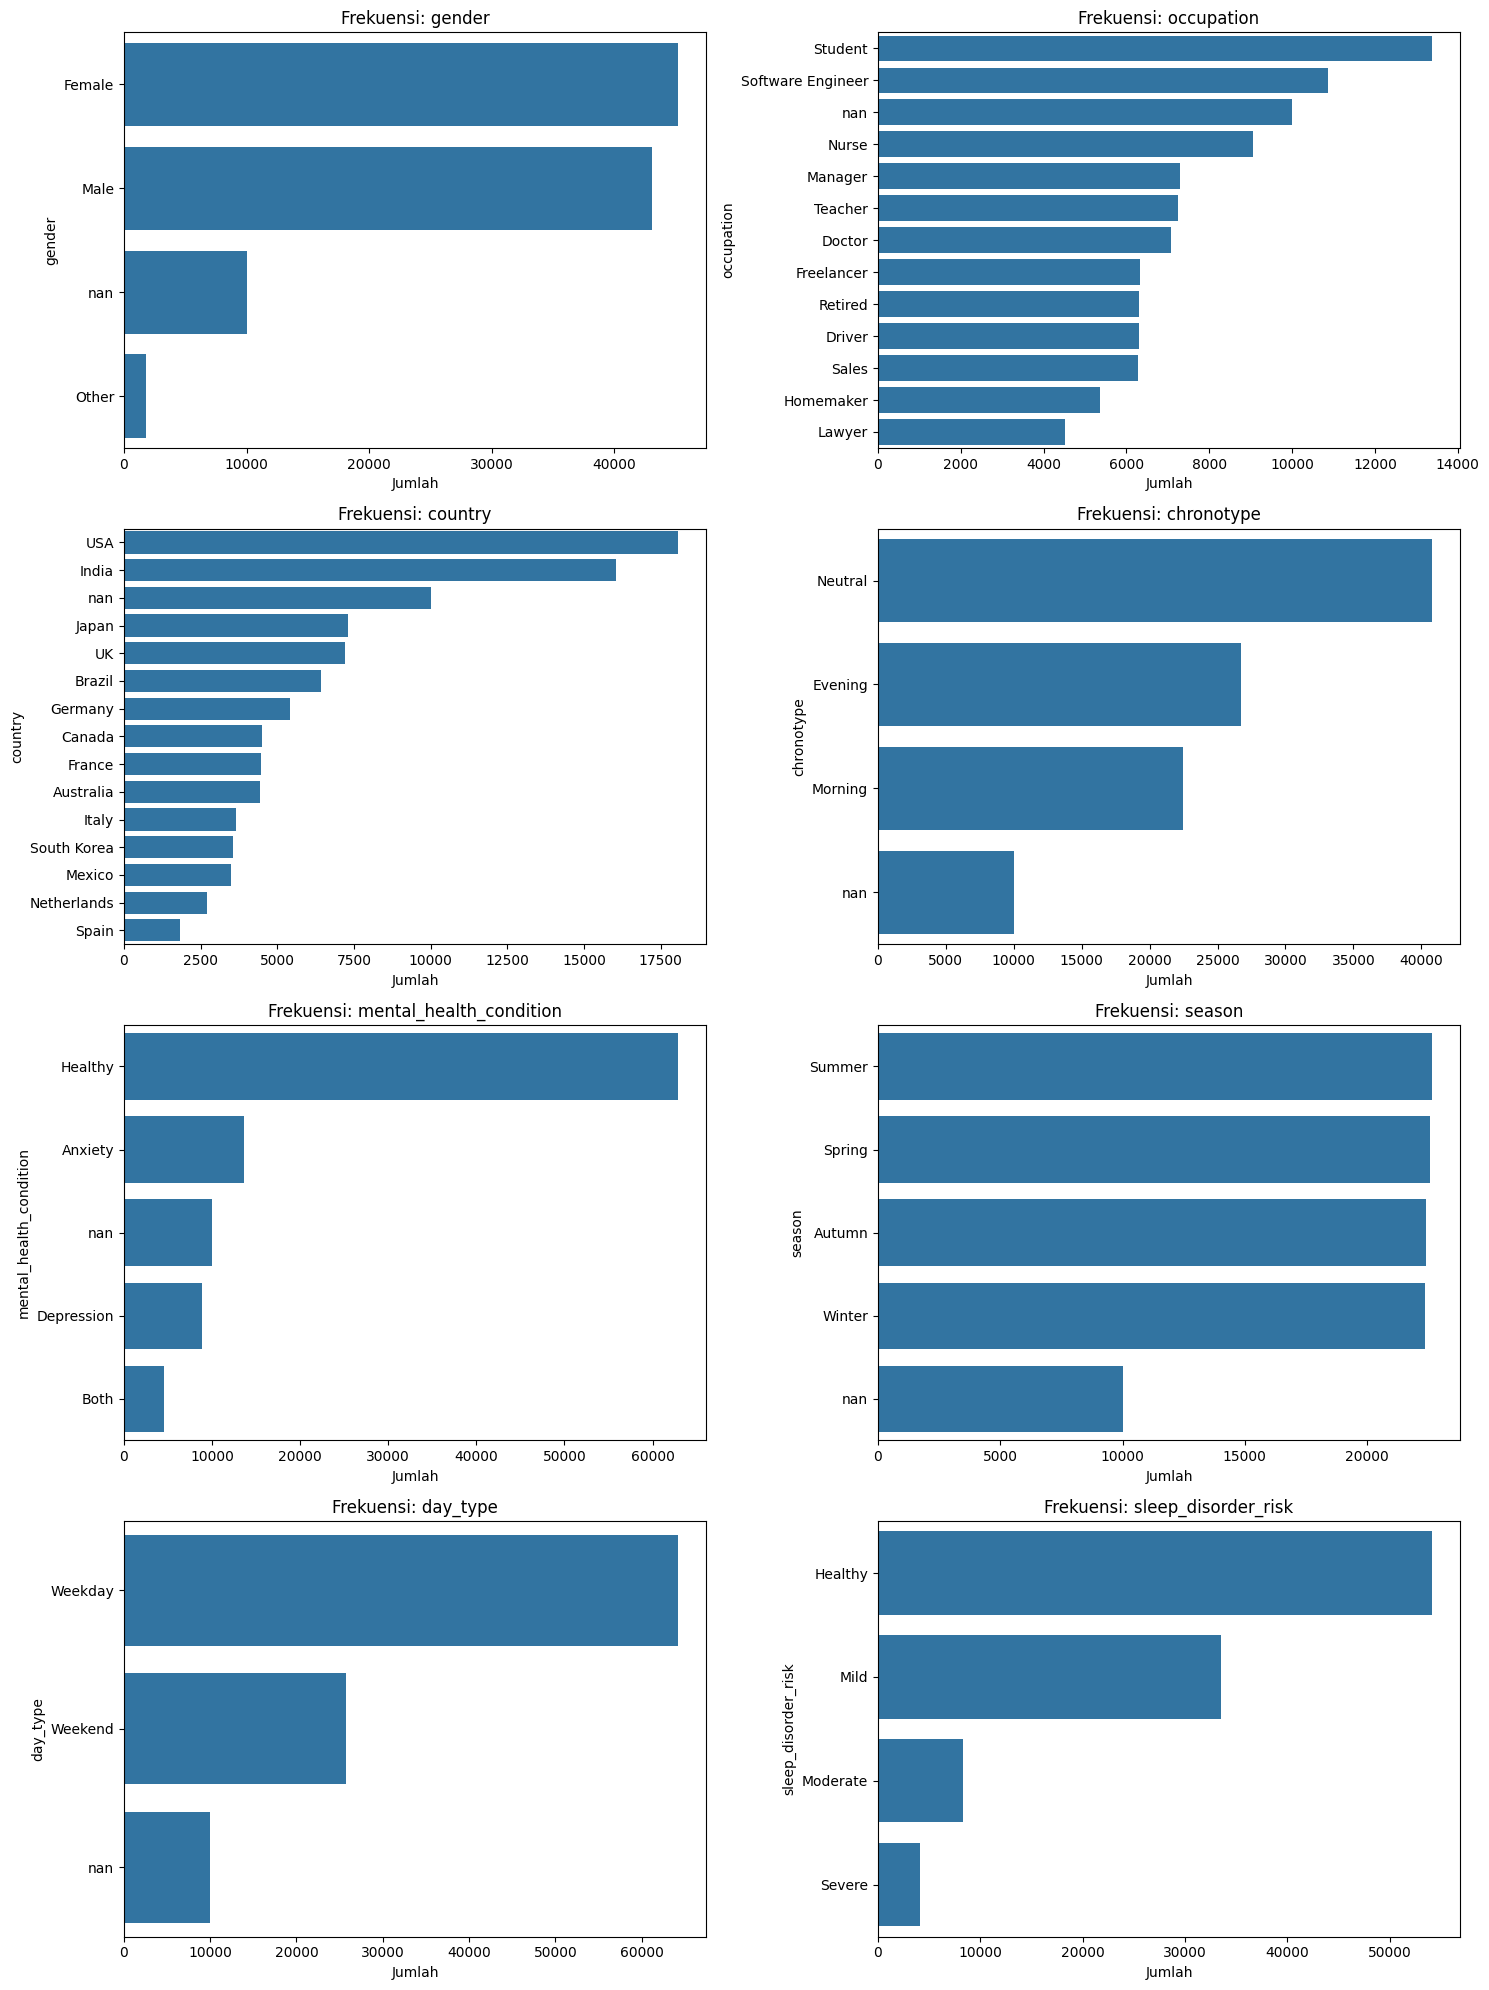

In [30]:
if kolom_kategorikal:
    ncols = 2
    nrows = int(np.ceil(len(kolom_kategorikal) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, kolom in enumerate(kolom_kategorikal):
        frek = df[kolom].value_counts(dropna=False).head(15)
        sns.barplot(x=frek.values, y=frek.index.astype(str), ax=axes[i])
        axes[i].set_title(f"Frekuensi: {kolom}")
        axes[i].set_xlabel("Jumlah")
        axes[i].set_ylabel(kolom)

    for j in range(len(kolom_kategorikal), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

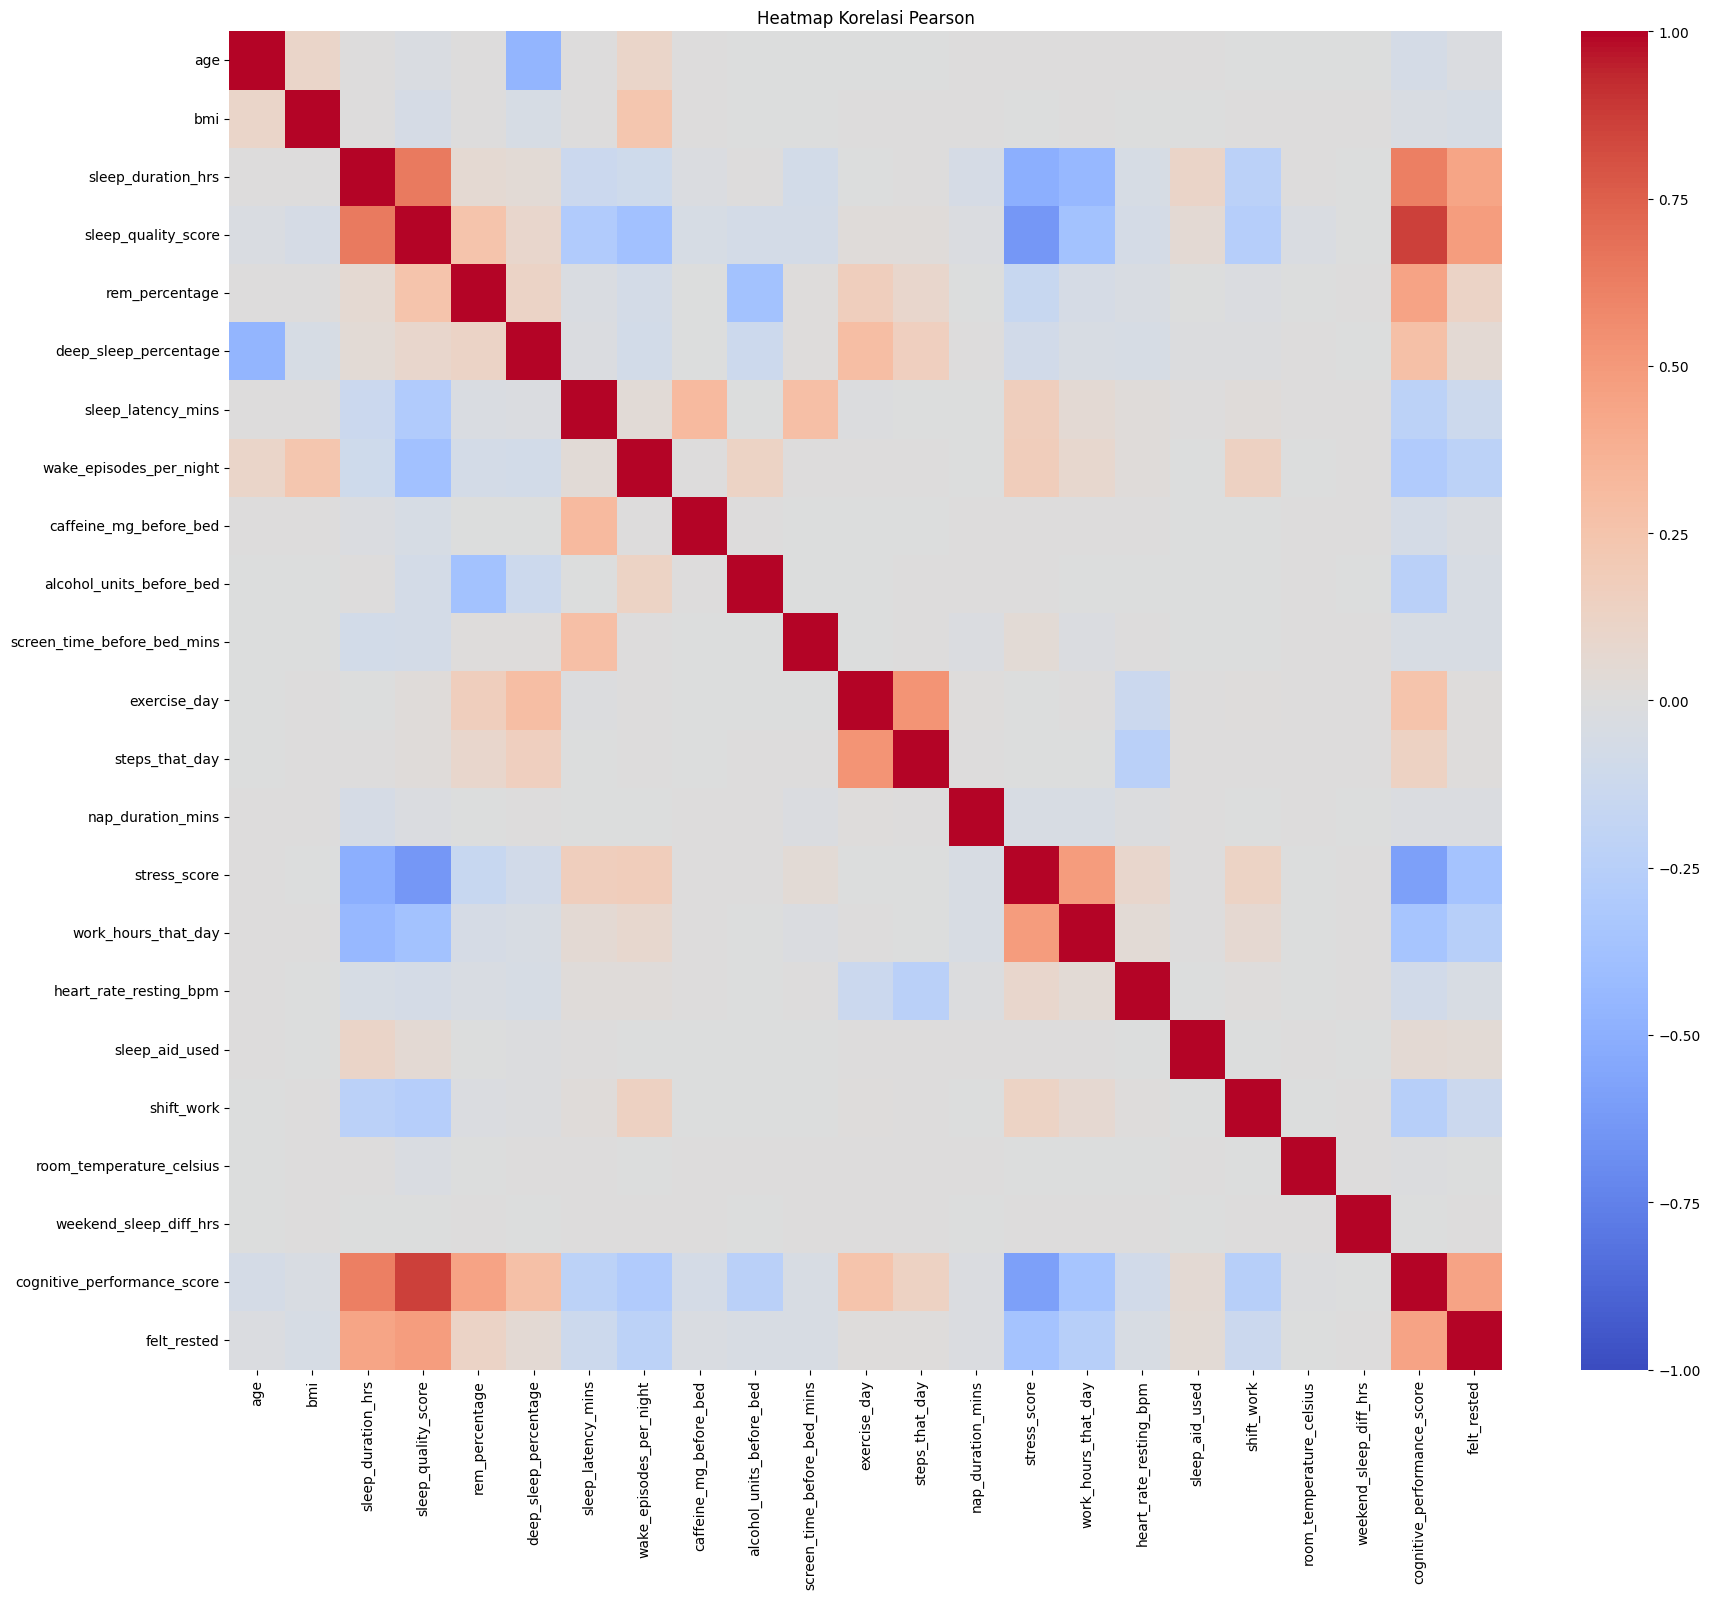

In [31]:
kolom_korelasi = [c for c in kolom_numerik if c != "person_id"]

if len(kolom_korelasi) >= 2:
    corr = df[kolom_korelasi].corr(method="pearson")
    plt.figure(figsize=(max(12, len(kolom_korelasi) * 0.8), max(9, len(kolom_korelasi) * 0.7)))
    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        annot=(len(kolom_korelasi) <= 15),
        fmt=".2f"
    )
    plt.title("Heatmap Korelasi Pearson")
    plt.tight_layout()
    plt.show()

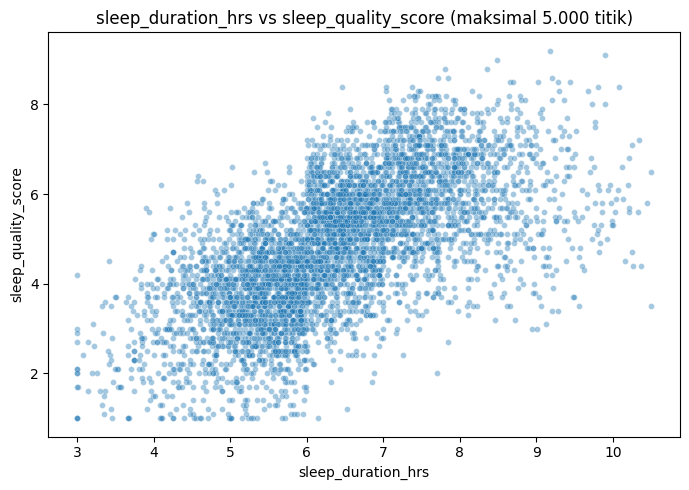

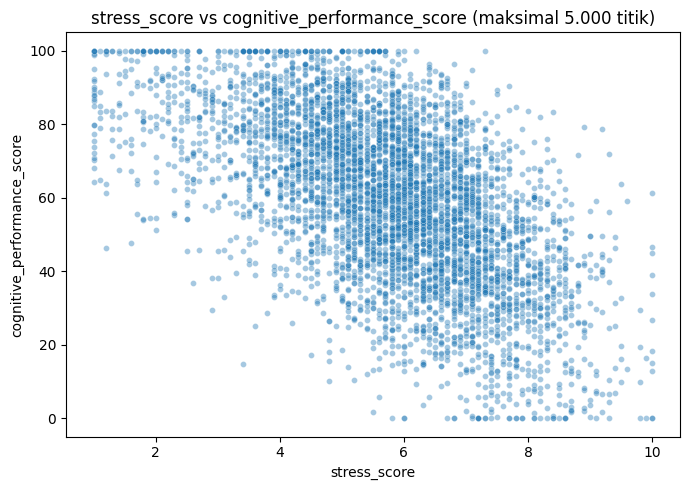

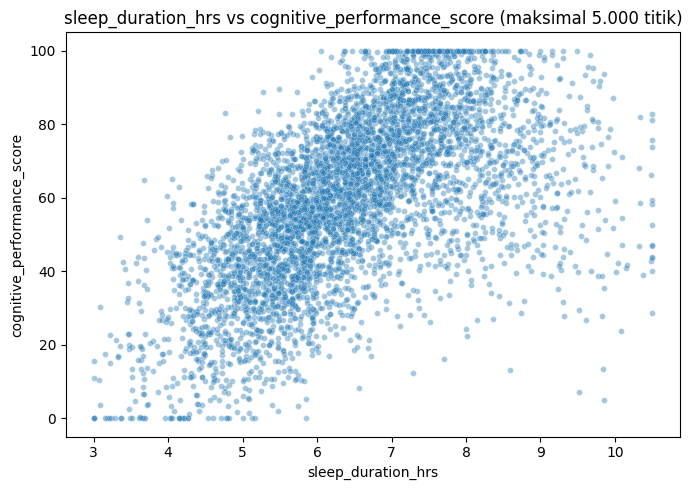

In [32]:
pasangan = [
    ("sleep_duration_hrs", "sleep_quality_score"),
    ("stress_score", "cognitive_performance_score"),
    ("sleep_duration_hrs", "cognitive_performance_score")
]

for x_col, y_col in pasangan:
    if x_col in df.columns and y_col in df.columns:
        sampel = df[[x_col, y_col]].dropna()
        if len(sampel) > 5000:
            sampel = sampel.sample(5000, random_state=42)

        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=sampel, x=x_col, y=y_col, alpha=0.4, s=18)
        plt.title(f"{x_col} vs {y_col} (maksimal 5.000 titik)")
        plt.tight_layout()
        plt.show()

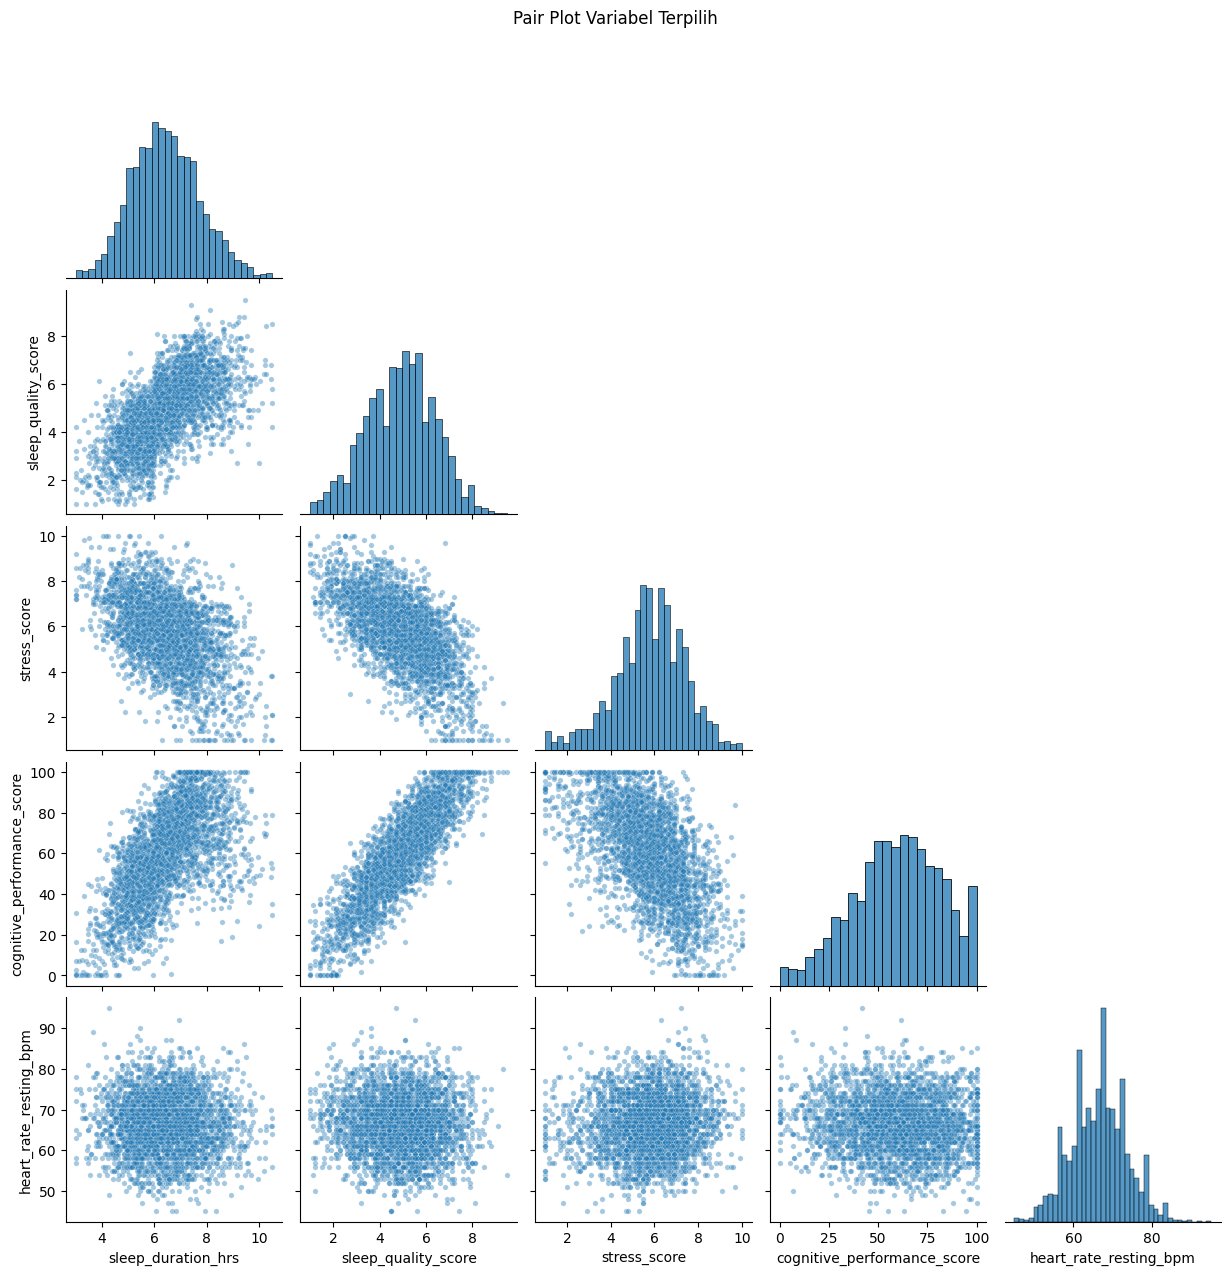

In [33]:
kolom_pair = [
    c for c in [
        "sleep_duration_hrs",
        "sleep_quality_score",
        "stress_score",
        "cognitive_performance_score",
        "heart_rate_resting_bpm"
    ] if c in df.columns
]

if len(kolom_pair) >= 2:
    data_pair = df[kolom_pair].dropna()
    if len(data_pair) > 3000:
        data_pair = data_pair.sample(3000, random_state=42)
    sns.pairplot(data_pair, diag_kind="hist", corner=True, plot_kws={"alpha": 0.4, "s": 15})
    plt.suptitle("Pair Plot Variabel Terpilih", y=1.02)
    plt.show()

**RINGKASAN INFORMASI SEMUA DATA**

In [34]:
total_missing = int(df.isna().sum().sum())
persen_sel_missing = total_missing / df.size * 100 if df.size else 0
jumlah_duplikat = int(df.duplicated().sum())
persen_duplikat = jumlah_duplikat / len(df) * 100 if len(df) else 0

print("=" * 60)
print("RINGKASAN DATA UNDERSTANDING — GANGGUAN TIDUR")
print("=" * 60)
print(f"Jumlah observasi                  : {len(df):,}")
print(f"Jumlah kolom                      : {df.shape[1]}")
print(f"Kolom numerik                     : {len(kolom_numerik)}")
print(f"Kolom kategorikal/non-numerik     : {len(kolom_kategorikal)}")
print(f"Total sel                         : {df.size:,}")
print(f"Total missing value               : {total_missing:,}")
print(f"Persentase sel yang missing       : {persen_sel_missing:.2f}%")
print(f"Baris duplikat identik             : {jumlah_duplikat:,} ({persen_duplikat:.2f}%)")

if target in df.columns:
    print("\nDistribusi target:")
    print(df[target].value_counts(dropna=False))
    print("\nPersentase target:")
    print((df[target].value_counts(normalize=True, dropna=False) * 100).round(2))

if "person_id" in df.columns:
    print("\nMissing person_id:", int(df["person_id"].isna().sum()))

print("=" * 60)

RINGKASAN DATA UNDERSTANDING — GANGGUAN TIDUR
Jumlah observasi                  : 100,000
Jumlah kolom                      : 32
Kolom numerik                     : 24
Kolom kategorikal/non-numerik     : 8
Total sel                         : 3,200,000
Total missing value               : 310,000
Persentase sel yang missing       : 9.69%
Baris duplikat identik             : 0 (0.00%)

Distribusi target:
sleep_disorder_risk
Healthy     54156
Mild        33479
Moderate     8299
Severe       4066
Name: count, dtype: int64

Persentase target:
sleep_disorder_risk
Healthy     54.16
Mild        33.48
Moderate     8.30
Severe       4.07
Name: proportion, dtype: float64

Missing person_id: 10000


In [35]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Tulis semua kolom target yang mau kamu cek di dalam list ini
# daftar_target = ['person_id', 'age', 'gender', 'occupation', 'bmi', 
#                  'country', 'sleep_duration_hrs', 'sleep_quality_score', 
#                  'rem_percentage', 'deep_sleep_percentage', 'sleep_latency_mins',
#                  'wake_episodes_per_night', 'caffeine_mg_before_bed',
#                  'alcohol_units_before_bed', 'screen_time_before_bed_mins', 
#                  'exercise_day', 'steps_that_day', 'nap_duration_mins', 
#                  'stress_score', 'work_hours_that_day', 'chronotype', 
#                  'mental_health_condition', 'heart_rate_resting_bpm', 
#                  'sleep_aid_used', 'shift_work', 'room_temperature_celsius', 
#                  'weekend_sleep_diff_hrs', 'season', 'day_type',
#                  'cognitive_performance_score', 'sleep_disorder_risk', 
#                  'felt_rested]

# # Looping untuk tiap kolom di dalam list
# for kolom_target in daftar_target:
#     fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#     # 1. Bar Chart / Countplot
#     sns.countplot(data=df, x=kolom_target, ax=axes[0], palette='Set2')
#     axes[0].set_title(f'Jumlah Data per Kelas ({kolom_target})')
#     axes[0].set_xlabel('Kategori')
#     axes[0].set_ylabel('Jumlah')

#     # Angka di atas batang
#     for p in axes[0].patches:
#         axes[0].annotate(f'{int(p.get_height())}', 
#                         (p.get_x() + p.get_width() / 2., p.get_height()), 
#                         ha='center', va='bottom')

#     # 2. Pie Chart
#     df[kolom_target].value_counts().plot.pie(
#         autopct='%1.1f%%', 
#         ax=axes[1], 
#         startangle=90, 
#         colors=sns.color_palette('Set2'),
#         explode=[0.03] * df[kolom_target].nunique()
#     )
#     axes[1].set_title(f'Persentase Distribusi ({kolom_target})')
#     axes[1].set_ylabel('')

#     plt.tight_layout()
#     plt.show()